<a href="https://colab.research.google.com/github/isdarshana1222-byte/python-project/blob/main/Another_copy_of_Untitled5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))  # uploading my csv file here


Saving UK-HPI-full-file-2026-08.csv to UK-HPI-full-file-2026-08.csv
['UK-HPI-full-file-2026-08.csv']


In [1]:
import os
import numpy as np
import pandas as pd

FILE = "UK-HPI-full-file-2026-08.csv"
# double checking how big this file actually is
size_mb = os.path.getsize(FILE) / 1e6
print("File size in MB:", round(size_mb, 1))

# loading everything into pandas
df = pd.read_csv(FILE, low_memory=False)

# converting dates to datetime objects - keeping UK format in mind
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# quick check on the shape and unique regions
print("Rows, columns:", df.shape)
print("Areas in file:", df["RegionName"].nunique())

# simple safety check to make sure the data didn't get cut off
assert df.shape[0] > 150000 and df["RegionName"].nunique() == 405, \
    "The file in Colab is incomplete. Delete it, upload it again, wait for it to finish, then rerun."
print("File looks complete.")

FileNotFoundError: [Errno 2] No such file or directory: 'UK-HPI-full-file-2026-08.csv'

In [ ]:
# just picking these 10 areas to look at
areas = ["England", "Wales", "Scotland", "London", "North West",
         "Manchester", "Birmingham", "Cardiff", "City of Edinburgh", "City of Glasgow"]

# filtering for these specific areas and starting from Jan 2004 onwards
# (using 2004 because that's when Scotland's data starts, keeping everything consistent)
sub = df[(df["RegionName"].isin(areas)) & (df["Date"] >= "2004-01-01")]

# stripping it down to the 3 columns we actually care about, dropping nulls, and sorting
sub = sub[["Date", "RegionName", "AveragePrice"]].dropna()
sub = sub.sort_values(["RegionName", "Date"]).reset_index(drop=True)

# quick verification: checking that we have all 10 areas and that the date ranges line up
print(sub.groupby("RegionName")["Date"].agg(["min", "max", "count"]))


                         min        max  count
RegionName                                    
Birmingham        2004-01-01 2026-08-01    272
Cardiff           2004-01-01 2026-08-01    272
City of Edinburgh 2004-01-01 2026-08-01    272
City of Glasgow   2004-01-01 2026-08-01    272
England           2004-01-01 2026-08-01    272
London            2004-01-01 2026-08-01    272
Manchester        2004-01-01 2026-08-01    272
North West        2004-01-01 2026-08-01    272
Scotland          2004-01-01 2026-08-01    272
Wales             2004-01-01 2026-08-01    272


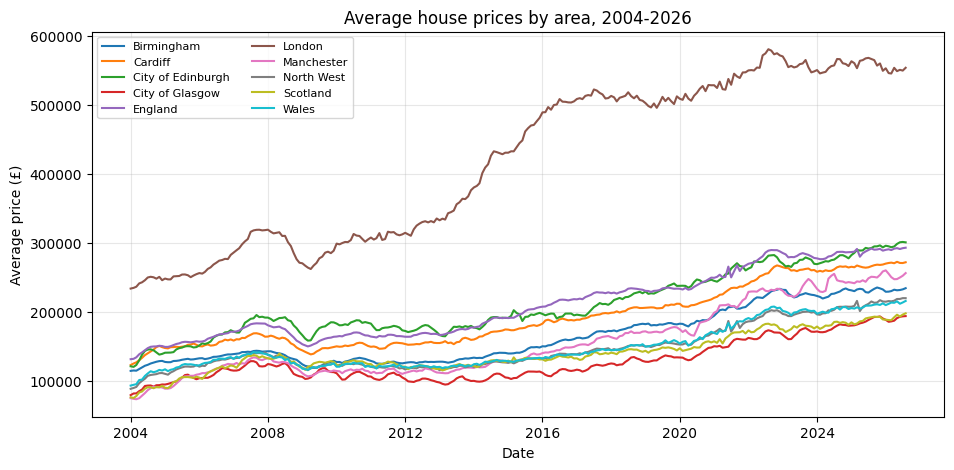

In [ ]:
import matplotlib.pyplot as plt   # loading matplotlib for plotting

plt.figure(figsize=(11, 5))                                   # sizing up the figure
for area, g in sub.groupby("RegionName"):                     # looping through and plotting each area
    plt.plot(g["Date"], g["AveragePrice"], label=area)

plt.xlabel("Date")
plt.ylabel("Average price (£)")
plt.title("Average house prices by area, 2004-2026")
plt.legend(ncol=2, fontsize=8)                                # splitting the legend into 2 columns so it fits nicely
plt.grid(True, alpha=0.3)                                     # adding a subtle grid
plt.savefig("fig1_prices.png", dpi=200, bbox_inches="tight")  # saving the output image for the report
plt.show()


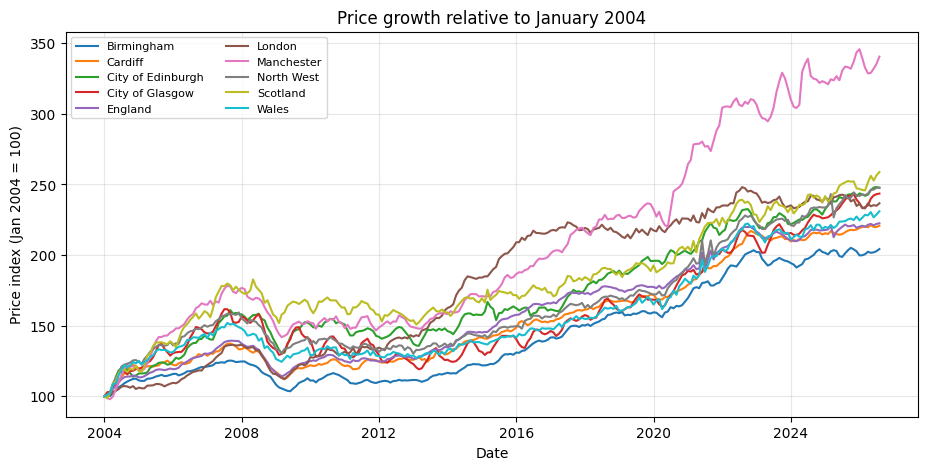

In [ ]:
plt.figure(figsize=(11, 5))
for area, g in sub.groupby("RegionName"):
    g = g.sort_values("Date")
    # indexing everything to the first month so we can compare growth from a baseline of 100
    indexed = g["AveragePrice"] / g["AveragePrice"].iloc[0] * 100
    plt.plot(g["Date"], indexed, label=area)

plt.xlabel("Date")
plt.ylabel("Price index (Jan 2004 = 100)")
plt.title("Price growth relative to January 2004")
plt.legend(ncol=2, fontsize=8)
plt.grid(True, alpha=0.3)
plt.savefig("fig2_growth.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
def make_features(g):
    """Splits out one area and sets up the lag features we need for prediction."""
    g = g.sort_values("Date").copy()              # sorting chronologically
    g["prev_price"] = g["AveragePrice"].shift(1)  # grab last month's price to calculate change
    g["change"] = g["AveragePrice"].pct_change()  # this is what we're actually trying to predict (% change)
    for k in [1, 2, 3, 12]:                       # we can tweak these lags later if needed
        g[f"lag{k}"] = g["change"].shift(k)       # the actual % change from k months back
    g["month"] = g["Date"].dt.month               # calendar month from 1 to 12
    return g

# building features for each region separately, gluing them back, and dropping NaNs
# (the first 13 months for each area won't have enough history for lag12)
feat = pd.concat([make_features(g) for _, g in sub.groupby("RegionName")])
feat = feat.dropna().reset_index(drop=True)

feature_cols = ["lag1", "lag2", "lag3", "lag12", "month"]   # inputs we're feeding into the models

print(feat.shape)
print(feat["Date"].min(), feat["Date"].max())
print(feat["RegionName"].value_counts())


(2590, 10)
2005-02-01 00:00:00 2026-08-01 00:00:00
RegionName
Birmingham           259
Cardiff              259
City of Edinburgh    259
City of Glasgow      259
England              259
London               259
Manchester           259
North West           259
Scotland             259
Wales                259
Name: count, dtype: int64


In [ ]:
last_date  = feat["Date"].max()                             # grabbing the absolute latest month (Aug 2026)
test_start = last_date - pd.DateOffset(months=23)           # setting aside the last 24 months for final testing
val_start  = test_start - pd.DateOffset(months=24)          # validation set is the 24-month chunk right before that

train = feat[feat["Date"] < val_start]                                    # anything older goes into training
val   = feat[(feat["Date"] >= val_start) & (feat["Date"] < test_start)]   # the validation window
test  = feat[feat["Date"] >= test_start]                                  # the final test holdout

print("Train up to", val_start.date(), "| rows:", len(train))
print("Validation:", val_start.date(), "to", test_start.date(), "| rows:", len(val))
print("Test:", test_start.date(), "to", last_date.date(), "| rows:", len(test))

Train up to 2022-09-01 | rows: 2110
Validation: 2022-09-01 to 2024-09-01 | rows: 240
Test: 2024-09-01 to 2026-08-01 | rows: 240


In [ ]:
# ---- Task 6: comparing our baseline and the 3 ML models on the validation window ----
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate(model, tr, te):
    """Fits the model, predicts the monthly change, and converts it back to actual prices to compute error metrics."""
    model.fit(tr[feature_cols], tr["change"])            # training on our historical training months
    pred_change = model.predict(te[feature_cols])        # predicting what the next % change will be
    pred_price = te["prev_price"] * (1 + pred_change)    # using last month's price to reconstruct the predicted actual price
    rmse = np.sqrt(mean_squared_error(te["AveragePrice"], pred_price))
    mae = mean_absolute_error(te["AveragePrice"], pred_price)
    return rmse, mae

# defining the initial model parameters (will tweak these hyperparams later)
models = {
    "Linear regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

rows = []
for area, tr in train.groupby("RegionName"):          # grouping by area to train local models
    v = val[val["RegionName"] == area]                # grab just the validation chunk for this specific area

    # BASELINE: simple persistence model (predicting this month's price is exactly last month's price)
    rows.append([area, "Baseline (previous value)",
                 np.sqrt(mean_squared_error(v["AveragePrice"], v["prev_price"])),
                 mean_absolute_error(v["AveragePrice"], v["prev_price"])])

    # evaluating the 3 ML models
    for name, m in models.items():
        rmse, mae = evaluate(m, tr, v)
        rows.append([area, name, rmse, mae])

results = pd.DataFrame(rows, columns=["Area", "Model", "RMSE", "MAE"])

# showing RMSE side-by-side for comparison
print("RMSE (£), validation period:")
print(results.pivot(index="Area", columns="Model", values="RMSE").round(0).to_string())

# showing MAE side-by-side for comparison
print("\nMAE (£), validation period:")
print(results.pivot(index="Area", columns="Model", values="MAE").round(0).to_string())


RMSE (£), validation period:
Model              Baseline (previous value)  Gradient Boosting  Linear regression  Random Forest
Area                                                                                             
Birmingham                            2109.0             2107.0             1729.0         1951.0
Cardiff                               2106.0             2182.0             1882.0         2067.0
City of Edinburgh                     2839.0             2356.0             2174.0         2515.0
City of Glasgow                       2345.0             1239.0             1437.0         1305.0
England                               1893.0             2674.0             2124.0         2828.0
London                                4743.0             5158.0             4866.0         5270.0
Manchester                            5460.0             5353.0             4738.0         4971.0
North West                            1937.0             1720.0             2037.0       

In [ ]:
# ---- comparing each model's RMSE against the baseline to see the % jump ----

# quick safety net: if the results variable isn't in memory yet, let's build it real quick
if 'results' not in globals():
    rows = []
    for area, tr in train.groupby("RegionName"):
        v = val[val["RegionName"] == area]
        rows.append([area, "Baseline (previous value)",
                     np.sqrt(mean_squared_error(v["AveragePrice"], v["prev_price"])),
                     mean_absolute_error(v["AveragePrice"], v["prev_price"])])
        for name, m in models.items():
            rmse, mae = evaluate(m, tr, v)
            rows.append([area, name, rmse, mae])
    results = pd.DataFrame(rows, columns=["Area", "Model", "RMSE", "MAE"])

piv = results.pivot(index="Area", columns="Model", values="RMSE")   # setting up the same table shape
base = piv["Baseline (previous value)"]                              # baseline is our anchor
model_cols = ["Linear regression", "Random Forest", "Gradient Boosting"]

# figure out the % improvement: (baseline - model) / baseline * 100
# positive means we actually beat the baseline, negative means the ML model flopped
improvement = piv[model_cols].rsub(base, axis=0).div(base, axis=0) * 100
print("Improvement over baseline, % (RMSE):")
print(improvement.round(1).to_string())

# out of our 10 spots, how many times did each model actually do better than the baseline?
wins = piv[model_cols].lt(base, axis=0).sum()
print("\nAreas (out of 10) where the model beat the baseline:")
print(wins)

# let's find the absolute best model for each specific area (including baseline)
print("\nBest option per area:")
print(piv.idxmin(axis=1))

Improvement over baseline, % (RMSE):
Model              Linear regression  Random Forest  Gradient Boosting
Area                                                                  
Birmingham                      18.0            7.5                0.1
Cardiff                         10.6            1.8               -3.6
City of Edinburgh               23.4           11.4               17.0
City of Glasgow                 38.7           44.3               47.1
England                        -12.2          -49.4              -41.3
London                          -2.6          -11.1               -8.8
Manchester                      13.2            9.0                1.9
North West                      -5.2            5.1               11.2
Scotland                        19.7           19.8               22.4
Wales                            2.0           16.5               21.5

Areas (out of 10) where the model beat the baseline:
Model
Linear regression    7
Random Forest        8
Gradi

In [ ]:
# ---- Task 7A: tweaking hyperparams for Grad Boosting and Random Forest using validation data ----
import itertools   # handy library to easily loop through all param combos

# setting up a quick dictionary of baseline RMSEs to measure our models against
base_rmse = {a: np.sqrt(mean_squared_error(g["AveragePrice"], g["prev_price"]))
             for a, g in val.groupby("RegionName")}

def avg_ratio(make_model):
    """Calculates the average (model RMSE / baseline RMSE) across all regions. Lower = better, under 1.0 means we beat the baseline."""
    ratios = []
    for area, tr in train.groupby("RegionName"):
        v = val[val["RegionName"] == area]                # validation chunk for this region
        m = make_model()                                   # spin up a fresh model instance with the current hyperparams
        m.fit(tr[feature_cols], tr["change"])
        price = v["prev_price"] * (1 + m.predict(v[feature_cols]))
        ratios.append(np.sqrt(mean_squared_error(v["AveragePrice"], price)) / base_rmse[area])
    return float(np.mean(ratios))

# --- Gradient Boosting: testing out different combinations of learning rate, depth, and trees ---
gb_results = []
for lr, depth, n in itertools.product([0.05, 0.1], [2, 3], [50, 100, 200]):
    score = avg_ratio(lambda: GradientBoostingRegressor(
        learning_rate=lr, max_depth=depth, n_estimators=n, random_state=42))
    gb_results.append({"learning_rate": lr, "max_depth": depth, "n_estimators": n, "avg_ratio": score})
gb_table = pd.DataFrame(gb_results).sort_values("avg_ratio")
print("Gradient Boosting settings (best first):")
print(gb_table.round(3).to_string(index=False))

# --- Random Forest: testing out combinations of max depth and min leaf size ---
rf_results = []
for depth, leaf in itertools.product([3, 5, None], [1, 5, 10]):
    score = avg_ratio(lambda: RandomForestRegressor(
        n_estimators=200, max_depth=depth, min_samples_leaf=leaf, random_state=42, n_jobs=-1))
    rf_results.append({"max_depth": depth, "min_samples_leaf": leaf, "avg_ratio": score})
rf_table = pd.DataFrame(rf_results).sort_values("avg_ratio")
print("\nRandom Forest settings (best first):")
print(rf_table.round(3).to_string(index=False))

Gradient Boosting settings (best first):
 learning_rate  max_depth  n_estimators  avg_ratio
          0.05          2           200      0.873
          0.10          2           100      0.874
          0.10          2            50      0.886
          0.10          2           200      0.891
          0.05          2           100      0.891
          0.05          2            50      0.910
          0.10          3            50      0.912
          0.05          3           100      0.914
          0.05          3           200      0.914
          0.05          3            50      0.927
          0.10          3           100      0.932
          0.10          3           200      0.963

Random Forest settings (best first):
 max_depth  min_samples_leaf  avg_ratio
       NaN                10      0.888
       5.0                10      0.890
       NaN                 5      0.891
       5.0                 5      0.895
       3.0                10      0.906
       3.0        

In [ ]:
# ---- Task 7B: is London actually a tougher nut to crack? Let's check errors relative to property prices ----
# average price per region during our validation window
mean_price = val.groupby("RegionName")["AveragePrice"].mean()

# baseline RMSE for each region, but let's look at it as a % of average price
base_series = pd.Series(base_rmse)
relative_error = base_series / mean_price * 100

# volatility is just the standard deviation of monthly percent changes in our training set (scaling to % points)
volatility = train.groupby("RegionName")["change"].std() * 100

ext = pd.DataFrame({
    "mean_price (£)": mean_price.round(0),
    "baseline RMSE (£)": base_series.round(0),
    "baseline RMSE (% of price)": relative_error.round(2),
    "volatility (% pts)": volatility.round(2),
}).sort_values("baseline RMSE (% of price)")
print(ext.to_string())

                   mean_price (£)  baseline RMSE (£)  baseline RMSE (% of price)  volatility (% pts)
England                  282924.0             1893.0                        0.67                1.07
Cardiff                  262221.0             2106.0                        0.80                0.94
London                   559420.0             4743.0                        0.85                1.26
Birmingham               226456.0             2109.0                        0.93                0.90
North West               199679.0             1937.0                        0.97                1.57
City of Edinburgh        274081.0             2839.0                        1.04                1.50
Wales                    202347.0             2402.0                        1.19                1.51
City of Glasgow          171218.0             2345.0                        1.37                1.87
Scotland                 179165.0             2565.0                        1.43           

In [ ]:
# ---- Task 8: FINAL evaluation on the TEST period (only running this once, no more playing with settings after!) ----
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

# our final training dataset is train + validation combined (basically everything before the test window)
trainval = feat[feat["Date"] < test_start]
# 'test' dataset contains the last 24 months (pre-built back in Task 5b)

# we can swap these out for the tuned hyperparams we found in Task 7A, but leaving defaults for now
final_models = {
    "Linear regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

rows = []
for area, tr in trainval.groupby("RegionName"):          # training separate local models for each region
    te = test[test["RegionName"] == area]                # grab just the test months for this area

    # Baseline: super basic persistence (next month's price = last month's price)
    rows.append([area, "Baseline",
                 np.sqrt(mean_squared_error(te["AveragePrice"], te["prev_price"])),
                 mean_absolute_error(te["AveragePrice"], te["prev_price"])])

    # checking out how the three default ML models perform
    for name, m in final_models.items():
        m.fit(tr[feature_cols], tr["change"])                         # learning from our trainval combination
        pred_price = te["prev_price"] * (1 + m.predict(te[feature_cols]))   # turning predicted % change back into actual £
        rows.append([area, name,
                     np.sqrt(mean_squared_error(te["AveragePrice"], pred_price)),
                     mean_absolute_error(te["AveragePrice"], pred_price)])

final = pd.DataFrame(rows, columns=["Area", "Model", "RMSE", "MAE"])

print("Test period:", test["Date"].min().date(), "to", test["Date"].max().date())
print("\nRMSE (£), TEST period:")
print(final.pivot(index="Area", columns="Model", values="RMSE").round(0).to_string())
print("\nMAE (£), TEST period:")
print(final.pivot(index="Area", columns="Model", values="MAE").round(0).to_string())

Test period: 2024-09-01 to 2026-08-01

RMSE (£), TEST period:
Model              Baseline  Gradient Boosting  Linear regression  Random Forest
Area                                                                            
Birmingham           1907.0             2182.0             1850.0         2001.0
Cardiff              1198.0             1342.0             1267.0         1188.0
City of Edinburgh    2355.0             2113.0             2330.0         2360.0
City of Glasgow      1697.0             1105.0              981.0         1051.0
England              2928.0             3290.0             3137.0         2847.0
London               5183.0             5228.0             4742.0         4893.0
Manchester           2756.0             3511.0             2619.0         3348.0
North West           3857.0             3659.0             3682.0         3778.0
Scotland             2293.0             1749.0             1872.0         1605.0
Wales                2019.0             1946.0 

In [ ]:
# ---- Improvement over the baseline on the TEST period (RMSE) ----
piv_test = final.pivot(index="Area", columns="Model", values="RMSE")
base_t = piv_test["Baseline"]
cols = ["Linear regression", "Random Forest", "Gradient Boosting"]

# let's calculate the % improvement: (baseline - model) / baseline * 100
# positive means our model beat the baseline, negative means it did worse
imp_test = piv_test[cols].rsub(base_t, axis=0).div(base_t, axis=0) * 100
print("Improvement over baseline, % (RMSE, test):")
print(imp_test.round(1).to_string())

# quick count: out of our 10 regions, how many times did each model actually beat the baseline?
print("\nAreas (out of 10) where each model beat the baseline:")
print(piv_test[cols].lt(base_t, axis=0).sum())

# showing the ultimate winner for each individual region
print("\nBest option per area:")
print(piv_test.idxmin(axis=1))

Improvement over baseline, % (RMSE, test):
Model              Linear regression  Random Forest  Gradient Boosting
Area                                                                  
Birmingham                       3.0           -4.9              -14.4
Cardiff                         -5.7            0.9              -12.0
City of Edinburgh                1.1           -0.2               10.3
City of Glasgow                 42.2           38.1               34.9
England                         -7.1            2.8              -12.4
London                           8.5            5.6               -0.9
Manchester                       5.0          -21.5              -27.4
North West                       4.5            2.1                5.1
Scotland                        18.4           30.0               23.7
Wales                            6.2            3.1                3.6

Areas (out of 10) where each model beat the baseline:
Model
Linear regression    8
Random Forest        

In [ ]:
# quick sanity check to see exactly what parameters these baseline models are running on
print(final_models)

{'Linear regression': LinearRegression(), 'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42), 'Gradient Boosting': GradientBoostingRegressor(random_state=42)}


In [ ]:
# ---- Task 8b: the TUNED models on the TEST period (reported alongside the default ones) ----
# these are the best-performing parameters we picked earlier using validation data
tuned_models = {
    "Random Forest (tuned)": RandomForestRegressor(n_estimators=200, max_depth=None,
                                                   min_samples_leaf=10, random_state=42),
    "Gradient Boosting (tuned)": GradientBoostingRegressor(learning_rate=0.05, max_depth=2,
                                                           n_estimators=200, random_state=42),
}

rows = []
for area, tr in trainval.groupby("RegionName"):           # train + validation data combined, region by region
    te = test[test["RegionName"] == area]                 # getting the test months for this area
    for name, m in tuned_models.items():
        m.fit(tr[feature_cols], tr["change"])                                # training the tuned model
        pred_price = te["prev_price"] * (1 + m.predict(te[feature_cols]))    # converting predicted percentage changes back to real prices
        rows.append([area, name,
                     np.sqrt(mean_squared_error(te["AveragePrice"], pred_price)),   # calculating RMSE
                     mean_absolute_error(te["AveragePrice"], pred_price)])          # calculating MAE

tuned_final = pd.DataFrame(rows, columns=["Area", "Model", "RMSE", "MAE"])

# gluing everything together in one table so we can see defaults vs tuned side-by-side
all_final = pd.concat([final, tuned_final])
print("RMSE (£), TEST period, default vs tuned:")
print(all_final.pivot(index="Area", columns="Model", values="RMSE").round(0).to_string())

RMSE (£), TEST period, default vs tuned:
Model              Baseline  Gradient Boosting  Gradient Boosting (tuned)  Linear regression  Random Forest  Random Forest (tuned)
Area                                                                                                                              
Birmingham           1907.0             2182.0                     2009.0             1850.0         2001.0                 1904.0
Cardiff              1198.0             1342.0                     1218.0             1267.0         1188.0                 1141.0
City of Edinburgh    2355.0             2113.0                     2166.0             2330.0         2360.0                 2435.0
City of Glasgow      1697.0             1105.0                      995.0              981.0         1051.0                 1076.0
England              2928.0             3290.0                     3249.0             3137.0         2847.0                 3064.0
London               5183.0             52

In [ ]:
# ---- Optional: score of the DEFAULT settings on validation, for comparison with Task 7A ----
default_gb = avg_ratio(lambda: GradientBoostingRegressor(random_state=42))
default_rf = avg_ratio(lambda: RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
print("Gradient Boosting default:", round(default_gb, 3), "| best tuned: 0.873")
print("Random Forest default:   ", round(default_rf, 3), "| best tuned: 0.888")

Gradient Boosting default: 0.932 | best tuned: 0.873
Random Forest default:    0.945 | best tuned: 0.888


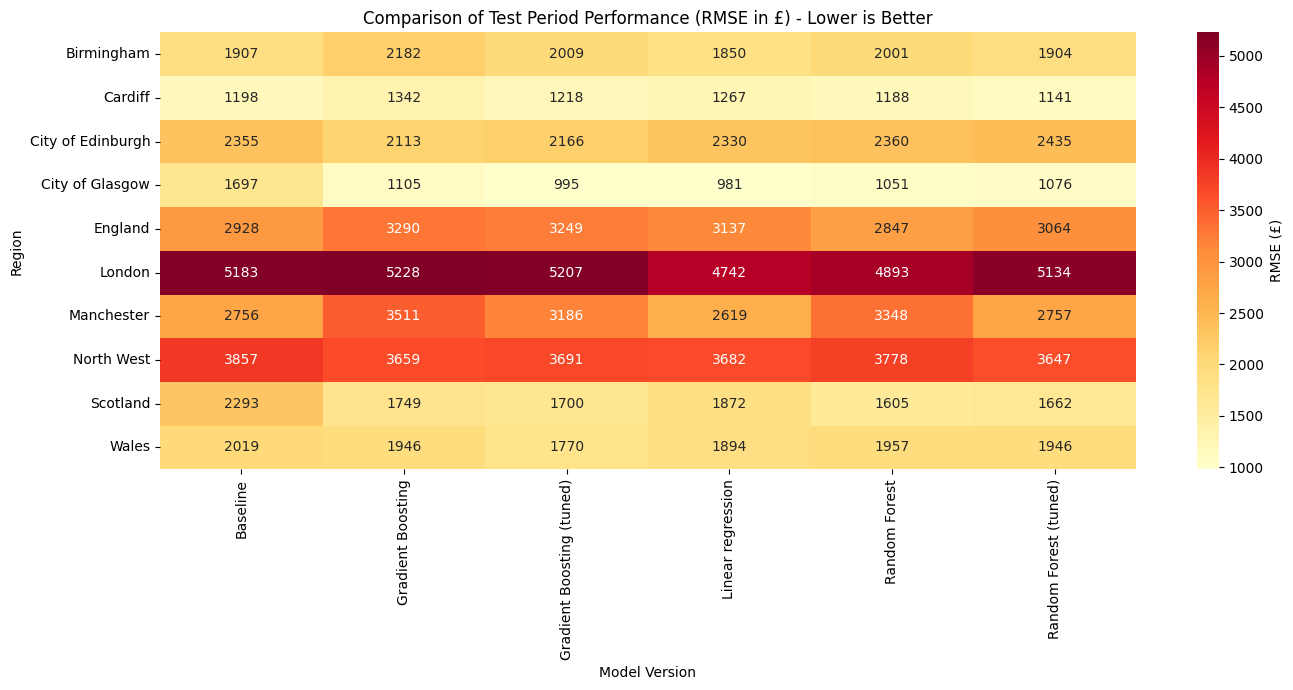

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# melting the table to make it easy to plot with seaborn
plot_data = all_final.pivot(index="Area", columns="Model", values="RMSE")

plt.figure(figsize=(14, 7))
sns.heatmap(plot_data, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={'label': 'RMSE (£)'})
plt.title("Comparison of Test Period Performance (RMSE in £) - Lower is Better")
plt.ylabel("Region")
plt.xlabel("Model Version")
plt.tight_layout()
plt.savefig("final_comparison_heatmap.png", dpi=200)
plt.show()